# 🎲 Notebook 1 — Monte Carlo Warm-Up
**Monte Carlo for Polymer Reaction Engineering · a hands-on mini-course**

> Never used Monte Carlo before? Start here. No polymers yet — just dice, darts and coins.

| | |
|---|---|
| ⏱ Time | ~20 min |
| 🎯 You will learn | the **4 tricks** that every algorithm in the course is built from |
| 📖 Companion book | *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture* |

**How to use this notebook:** in Colab, click **Runtime → Run all**, then read from top to bottom. Change the numbers in any cell and run it again — that's the whole point.

### 🗺️ The course
1. **Monte Carlo warm-up** ← *you are here*
2. Chain growth & molecular weight distributions
3. Copolymers & composition
4. Long-chain branching
5. Step growth & gelation
6. Gillespie kinetic Monte Carlo (time!)
7. Gillespie minis: ATRP & polymer degradation

## What *is* Monte Carlo?
- Use **random numbers** to imitate a process that has chance in it.
- Repeat it **many times**.
- **Count** what happened → averages and distributions.

Polymerization is full of chance: *will this chain add one more monomer, or stop?* Monte Carlo lets us answer by simply... asking the dice, a million times.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)                     # same "random" numbers every run → reproducible
plt.rcParams.update({"figure.figsize": (6, 3.6), "axes.grid": True, "grid.alpha": 0.3})

## 1 · The random number `Rnd`
Everything starts with a number picked uniformly between 0 and 1. In the book's algorithms it is written `Rnd ← random(0,1)`.

[0.639, 0.025, 0.275, 0.223, 0.736, 0.677, 0.892, 0.087]


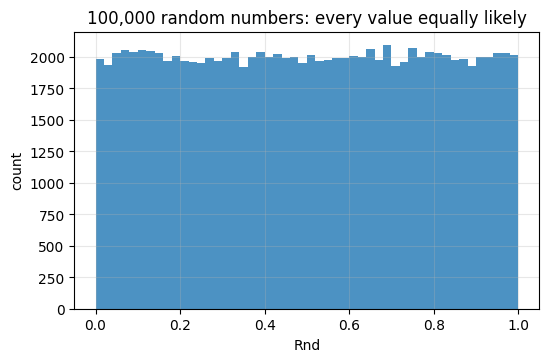

In [2]:
print([round(random.random(), 3) for _ in range(8)])

rnd = [random.random() for _ in range(100_000)]
plt.hist(rnd, bins=50, color="tab:blue", alpha=0.8)
plt.title("100,000 random numbers: every value equally likely")
plt.xlabel("Rnd"); plt.ylabel("count"); plt.show()

## 2 · Trick #1 — "Does it happen?"  `if Rnd ≤ P`
An event with probability `P` happens when `Rnd ≤ P`. This **single line** is the heart of chapters on chain growth.

Example: a coin with `P = 0.5`. Watch the fraction of heads settle down as we flip more (the *law of large numbers*).

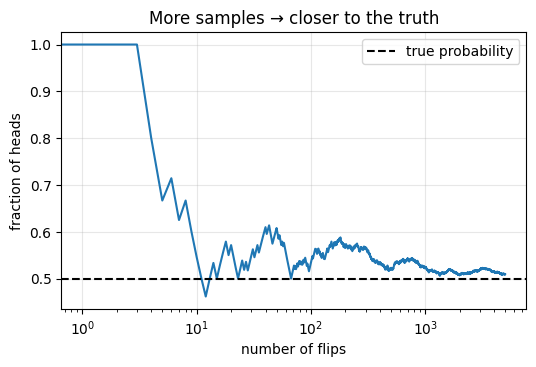

In [3]:
P = 0.5
heads, running = 0, []
for i in range(1, 5001):
    if random.random() <= P:      # ← Trick #1
        heads += 1
    running.append(heads / i)

plt.plot(running)
plt.axhline(P, color="k", ls="--", label="true probability")
plt.xscale("log"); plt.xlabel("number of flips"); plt.ylabel("fraction of heads")
plt.title("More samples → closer to the truth"); plt.legend(); plt.show()

## 3 · Trick #2 — estimate a number by counting (darts for π)
Throw darts at a 1×1 square. The fraction landing inside the quarter circle is π/4.

**Key lesson:** the error shrinks like **1/√N**. 100× more samples → only 10× more accurate. You will see this "noise" in every distribution later.

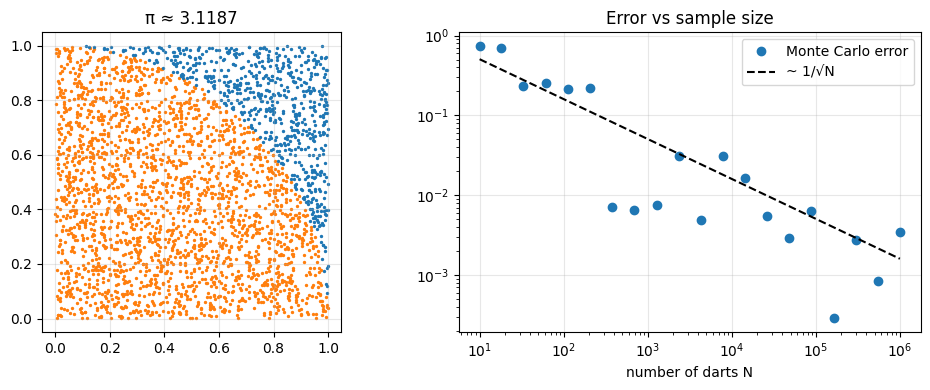

In [4]:
N = 3000
x = np.array([random.random() for _ in range(N)])
y = np.array([random.random() for _ in range(N)])
inside = x**2 + y**2 <= 1

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(x[inside], y[inside], s=2, c="tab:orange")
ax[0].scatter(x[~inside], y[~inside], s=2, c="tab:blue")
ax[0].set_aspect("equal"); ax[0].set_title(f"π ≈ {4*inside.mean():.4f}")

Ns = np.logspace(1, 6, 20).astype(int)
errors = [abs(4*np.mean(np.random.rand(k)**2 + np.random.rand(k)**2 <= 1) - np.pi) for k in Ns]
ax[1].loglog(Ns, errors, "o", label="Monte Carlo error")
ax[1].loglog(Ns, 1.6/np.sqrt(Ns), "k--", label="~ 1/√N")
ax[1].set_xlabel("number of darts N"); ax[1].legend(); ax[1].set_title("Error vs sample size")
plt.tight_layout(); plt.show()

## 4 · Trick #3 — "Which one happens?" (the roulette wheel)
Several possible events, each with a weight (a rate). Line them up end-to-end, throw `Rnd × total`, and see where it lands.

This is exactly the *"Find reaction j such that Σ…"* line in every Gillespie algorithm of the book. Here: a toy reactor where propagation is much more likely than termination.

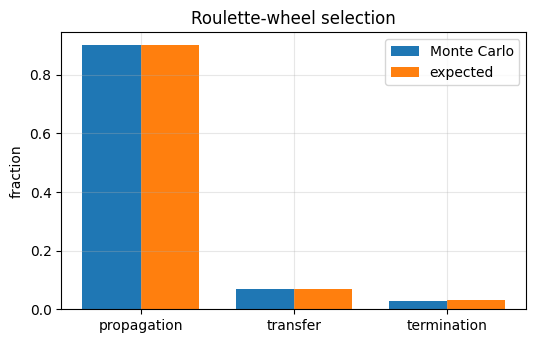

In [5]:
events = ["propagation", "transfer", "termination"]
rates  = np.array([90.0, 7.0, 3.0])         # any positive numbers (relative weights)

def pick_event(rates):
    cum = np.cumsum(rates)
    r = random.random() * cum[-1]           # ← Rnd × R_total
    return int(np.searchsorted(cum, r))     # first j with cumulative sum ≥ r

counts = np.zeros(len(rates))
for _ in range(20_000):
    counts[pick_event(rates)] += 1

w = 0.38; idx = np.arange(len(events))
plt.bar(idx - w/2, counts/counts.sum(), w, label="Monte Carlo")
plt.bar(idx + w/2, rates/rates.sum(), w, label="expected")
plt.xticks(idx, events); plt.ylabel("fraction"); plt.legend(); plt.title("Roulette-wheel selection"); plt.show()

## 5 · Trick #4 — "When does it happen?" (waiting times)
If events happen at a total rate `R` (per second), the time until the next one is

$$\tau = \frac{1}{R}\ln\frac{1}{Rnd}$$

That's the *clock* of the Gillespie algorithm (Notebooks 6–7). Waiting times are short most of the time, occasionally long (an exponential distribution).

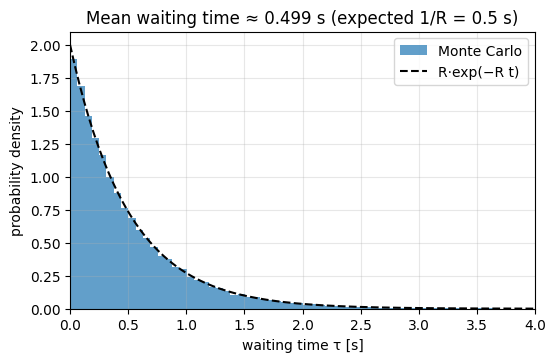

In [6]:
R = 2.0   # events per second
tau = [np.log(1/random.random()) / R for _ in range(50_000)]

t = np.linspace(0, 4, 200)
plt.hist(tau, bins=80, density=True, alpha=0.7, label="Monte Carlo")
plt.plot(t, R*np.exp(-R*t), "k--", label="R·exp(−R t)")
plt.xlim(0, 4); plt.xlabel("waiting time τ [s]"); plt.ylabel("probability density")
plt.title(f"Mean waiting time ≈ {np.mean(tau):.3f} s (expected 1/R = {1/R} s)"); plt.legend(); plt.show()

## 6 · Last example: who wins the dice game?
Maryam, Tala and Jad each roll two dice; the highest total wins (a tie means replay). What is each player's chance of winning?

Instead of working it out on paper, **play the game many times and count** (Trick #2).

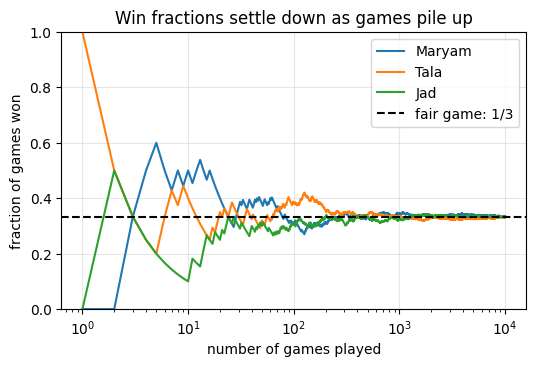

Maryam  won 33.6% of the games
Tala    won 33.1% of the games
Jad     won 33.3% of the games


In [7]:
players = ["Maryam", "Tala", "Jad"]

def play_game():
    while True:
        totals = [random.randint(1, 6) + random.randint(1, 6) for _ in players]
        best = max(totals)
        if totals.count(best) == 1:          # single winner, otherwise replay
            return totals.index(best)

N_games = 10_000
wins = np.zeros(len(players))
running = []
for g in range(1, N_games + 1):
    wins[play_game()] += 1
    running.append(wins / g)
running = np.array(running)

for k, name in enumerate(players):
    plt.plot(np.arange(1, N_games + 1), running[:, k], label=name)
plt.axhline(1/3, color="k", ls="--", label="fair game: 1/3")
plt.xscale("log"); plt.ylim(0, 1); plt.xlabel("number of games played"); plt.ylabel("fraction of games won")
plt.title("Win fractions settle down as games pile up"); plt.legend(); plt.show()
for name, w in zip(players, wins):
    print(f"{name:7s} won {w/N_games:.1%} of the games")

## ✅ Recap — your Monte Carlo toolbox
| Trick | Code | Used for |
|---|---|---|
| 1 · Does it happen? | `if random.random() <= P` | propagate or stop, which monomer adds |
| 2 · Count to estimate | repeat N times, average | averages, distributions (error ~ 1/√N) |
| 3 · Which one happens? | cumulative sum + `Rnd × total` | choosing the next reaction |
| 4 · When? | `τ = ln(1/Rnd)/R` | the clock in kinetic Monte Carlo |

### 🧪 Try it yourself
1. Make the coin unfair (`P = 0.3`). How many flips until you are within 1 % of 0.3?
2. In the dice game, let Jad roll three dice and keep the best two. How much does his chance of winning go up?
3. Play only 50 games several times. How much do the win fractions jump around?

➡️ **Next: Notebook 2 — Chain growth & molecular weight distributions**